# **Temel Kavramlar ve Temel Kütüphaneler**

Geleneksel programlamada kuralları (if/else) ve veriyi biz veririz, bilgisayar bize sonuç üretir. Makine Öğrenmesinde (Machine Learning) ise veriyi ve sonuçları bilgisayara veririz, bilgisayar kendi kendine kuralları (örüntüleri) bulur.

Temel Terimler:
Dataset (Veri Seti): Modelimizi eğitmek için kullandığımız örneklerin tamamı. Satırlar örnekleri, sütunlar ise özellikleri temsil eder.
Feature (Özellik / Girdi - X): Tahmin yapmak için kullandığımız bağımsız değişkenler (örneğin; bir oyuncunun günlük oynama süresi, ulaştığı seviye).
Label (Etiket / Çıktı - y): Tahmin etmeye çalıştığımız hedef değişken (örneğin; oyuncunun oyunu bırakıp bırakmayacağı veya oyuna ne kadar para harcayacağı).
Training (Eğitim): Modelin verideki örüntüleri öğrenme süreci. 

## **Temel Kütüphaneler: NumPy ve Pandas**

Python'da verileri listeler halinde tutmak, büyük veri setlerinde çok yavaştır. Bu yüzden arka planda inanılmaz hızlı çalışan ve veriyi kolayca manipüle etmemizi sağlayan kütüphaneler kullanırız.

NumPy (Numerical Python): Matematiksel işlemler ve çok boyutlu diziler (matrisler) için kullanılır. Makine öğrenmesi algoritmalarının temel yapıtaşıdır.
Pandas: Veri setlerini Excel gibi tablo formatında (DataFrame) tutmamızı, filtrelememizi ve temizlememizi sağlar.

In [ ]:
# NumPy kütüphanesini içeri aktarıyoruz ve genelde 'np' kısaltmasıyla kullanırız
import numpy as np

# Standart bir Python listesini NumPy dizisine (array) çevirelim
python_listesi = [1, 2, 3, 4, 5]
numpy_dizisi = np.array(python_listesi)

print("Python Listesi:", python_listesi)
print("NumPy Dizisi:", numpy_dizisi)

# NumPy'ın asıl gücü matrislerde ve hızlı matematikte yatar:
matris = np.array([[1, 2, 3], [4, 5, 6]])
print("2 Boyutlu Matris:\n", matris)

# Tüm elemanları aynı anda matematikten geçirebiliriz (Döngü kullanmadan!)
print("Matrisin 10 katı:\n", matris * 10)

In [ ]:
# Pandas kütüphanesini içeri aktarıyoruz ve genelde 'pd' kısaltmasıyla kullanırız
import pandas as pd

# Oyun dünyasından oyuncu metriklerini içeren örnek bir veri seti (sözlük) oluşturalım
veri = {
    'Oynanan_Oyun': ['Forza Horizon 5', 'GTA 5', 'Valorant', 'CS 2', 'Portal 2'],
    'Gunluk_Oynama_Dk': [120, 45, 180, 60, 90],
    'Ulasilan_Seviye': [257, 376, 450, 300, 40],
    'Oyun_Ici_Satin_Alma': [True, False, True, True, False] # Hedef değişkenimiz (Label) olabilir
}

# Bu veriyi Pandas DataFrame'ine (Excel tablosu gibi bir yapıya) çevirelim
df = pd.DataFrame(veri)

# Tablonun ilk 5 satırını ekrana yazdıralım
print("--- Oyuncu Veri Seti ---")
print(df.head())
# print yerine display kullanmak Jupyter'de tabloyu çok daha şık gösterir
display(df.head())

In [ ]:
# NumPy'ı eksik veri (NaN) oluşturmak için kullanacağız
import numpy as np

# Daha kapsamlı ve eksik veri içeren bir tablo oluşturalım
kapsamli_veri = {
    'Oyuncu_ID': [101, 102, 103, 104, 105, 106, 107],
    'Oynanan_Oyun': ['Valorant', 'CS 2', 'Valorant', 'CS 2', 'Valorant', 'CS 2', 'Valorant'],
    'Gunluk_Oynama_Dk': [120, 45, np.nan, 60, 90, 150, np.nan], # np.nan eksik (boş) veriyi temsil eder
    'Ulasilan_Seviye': [50, 120, 65, 300, 40, 450, 10],
    'Satin_Alma': [True, False, True, True, False, True, False]
}

df_oyuncular = pd.DataFrame(kapsamli_veri)
print("--- Kirli Veri Setimiz ---")
display(df_oyuncular)

# 1. Hangi kolonda kaç tane eksik veri var bulalım:
print("\nEksik Veri Sayısı:")
display(df_oyuncular.isna().sum())

# 2. Eksik verileri temizleme (Doldurma Yöntemi):
# Günlük oynama süresi boş olan oyunculara, tablodaki ortalama oynama süresini yazalım
ortalama_sure = df_oyuncular['Gunluk_Oynama_Dk'].mean()
df_oyuncular['Gunluk_Oynama_Dk'] = df_oyuncular['Gunluk_Oynama_Dk'].fillna(ortalama_sure)

print("\n--- Eksik Verileri Doldurulmuş Tablo ---")
display(df_oyuncular)

# 3. Filtreleme: Sadece 'CS 2' oynayan ve 100. seviyenin üstündeki oyuncuları bulalım
pro_oyuncular = df_oyuncular[(df_oyuncular['Oynanan_Oyun'] == 'CS 2') & (df_oyuncular['Ulasilan_Seviye'] > 100)]
print("\nSadece Seviyesi 100'den Büyük Olan Royal Match Oyuncuları:")
display(pro_oyuncular)

## **Gruplama (Groupby) ve Özellik Çıkarımı (Feature Engineering)**

Yapay zeka modelleri bazen elimizdeki ham veriden ziyade, o veriden türettiğimiz yeni bilgilere daha iyi tepki verir. Buna "Feature Engineering" (Özellik Mühendisliği) denir. 
Ayrıca `groupby` metodu ile SQL'dekine benzer şekilde verilerimizi kategorilerine göre gruplayıp istatistikler çıkarabiliriz.


In [ ]:
# 1. Gruplama (Groupby): Hangi oyunun oyuncuları ortalama ne kadar süre oynuyor?
oyun_istatistikleri = df_oyuncular.groupby('Oynanan_Oyun')['Gunluk_Oynama_Dk'].mean().reset_index()
print("Oyunlara Göre Ortalama Oynama Süreleri:")
display(oyun_istatistikleri)

# 2. Özellik Çıkarımı (Feature Engineering): Yeni bir kolon yaratalım.
# Eğer oyuncu günde 100 dakikadan fazla oynuyorsa 'Bagimli', az oynuyorsa 'Gundelik' etiketi verelim
# np.where(koşul, doğruysa_ne_yazılacak, yanlışsa_ne_yazılacak) şeklinde çalışır
df_oyuncular['Oyuncu_Tipi'] = np.where(df_oyuncular['Gunluk_Oynama_Dk'] > 100, 'Bagimli', 'Gundelik')

# 3. Satın alma oranlarına bakalım: Hangi oyuncu tipi daha çok para harcıyor?
satin_alma_oranlari = df_oyuncular.groupby('Oyuncu_Tipi')['Satin_Alma'].mean() * 100 # Yüzdeye çeviriyoruz

print("\n--- Analiz Edilmiş ve Yeni Özellik Eklenmiş Son Tablo ---")
display(df_oyuncular)

print("\nOyuncu Tipine Göre Satın Alma Oranları (%):")
display(satin_alma_oranlari)

## **Veri Görselleştirme: Matplotlib ve Seaborn**

Yapay zeka modelleri sayılarla konuşur ama biz insanlar şekillerle anlarız. Verimizdeki gizli eğilimleri görmek veya modelimizin ne kadar başarılı olduğunu sunmak için **Matplotlib** ve onun daha şık hali olan **Seaborn** kütüphanelerini kullanırız.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Oyuncuların seviyeleri ve bu seviyelere ulaşma süreleri hakkında sahte veriler üretelim
veri = pd.DataFrame({
    'Oyun_Suresi_Saat': np.random.randint(10, 100, 50),
})
# Süre arttıkça ulaşılan seviyeye biraz rastgelelik katarak bir formül yazalım
veri['Ulasilan_Seviye'] = veri['Oyun_Suresi_Saat'] * 1.5 + np.random.randint(-15, 15, 50)

# Seaborn ile şık bir dağılım (scatter) grafiği çizelim
sns.set_theme(style="whitegrid") # Arka planı ızgaralı yap
plt.figure(figsize=(10, 5)) # Grafiğin boyutu

sns.scatterplot(x='Oyun_Suresi_Saat', y='Ulasilan_Seviye', data=veri, color='blue', s=100)

plt.title("Oynama Süresi ve Ulaşılan Seviye İlişkisi", fontsize=15)
plt.xlabel("Oynama Süresi (Saat)", fontsize=12)
plt.ylabel("Ulaşılan Seviye", fontsize=12)

# Jupyter içinde grafiği göster
plt.show()

## **Klasik Makine Öğrenmesi: Scikit-Learn (sklearn)**

 Regresyon, Sınıflandırma, Karar Ağaçları ve Rastgele Ormanlar (Random Forests) gibi konuların tamamını **Scikit-Learn** ile yazarız. Bu kütüphane, çok karmaşık matematiksel algoritmaları 3-4 satır kodla kurmamızı sağlar.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Örnek Veri Seti (Features - X): [Oynama_Suresi, Harcanan_Para]
# Etiket (Label - y): Oyuncu oyunu bıraktı mı? (0: Hayır, 1: Evet)
X = [[10, 0], [120, 50], [15, 5], [300, 100], [5, 0], [200, 20]]
y = [1, 0, 1, 0, 1, 0] 

# 1. Modeli Tanımla
model = RandomForestClassifier(random_state=42)

# 2. Modeli Eğit (Fit metodu yapay zekanın kalbidir, veriye bakıp kuralı öğrenir)
model.fit(X, y)

# 3. Eğitilmiş modelden tahmin isteyelim
# Soru: 150 dakika oynamış ve 30 TL harcamış yeni bir oyuncu oyunu bırakır mı?
yeni_oyuncu = [[150, 30]]
tahmin = model.predict(yeni_oyuncu)

print("Yeni oyuncu oyunu bırakır mı? (1: Evet, 0: Hayır) -> Sonuç:", tahmin[0])

## **Derin Öğrenme: PyTorch**

Bilgisayarlı Görü (CNN) veya Doğal Dil İşleme (NLP) gibi kompleks görevlerde insan beynini taklit eden Yapay Sinir Ağları kullanırız. PyTorch, verileri GPU üzerinde inanılmaz hızlarda işlenen **Tensor** isimli matrislere çevirir.

In [ ]:
import torch
import torch.nn as nn

# Verilerimizi NumPy dizisi yerine PyTorch 'Tensor'lerine çeviriyoruz (GPU'da çalışabilmesi için)
# X girdilerimiz, y ise modelin bulmasını istediğimiz hedefler (Dikkat et, y = X'in 2 katı)
X = torch.tensor([[1.0], [2.0], [3.0], [4.0]])
y = torch.tensor([[2.0], [4.0], [6.0], [8.0]]) 

# En basit Sinir Ağı: Tek bir doğrusal (Linear) katman
sinir_agi_katmani = nn.Linear(in_features=1, out_features=1)

# Henüz eğitilmemiş modelimize 5 sayısını soralım (Normalde 10 demesi lazım)
test_verisi = torch.tensor([5.0])
rastgele_tahmin = sinir_agi_katmani(test_verisi)

# Not: Bu tahmin rastgeledir çünkü ağ henüz 'Loss.backward()' ile eğitilmedi (Geri Yayılım).
print("Eğitilmemiş Sinir Ağının 5.0 için tahmini:", rastgele_tahmin.item())

## **Doğal Dil İşleme (NLP): Hugging Face**

ChatGPT gibi gelişmiş dil modellerinin veya dil çevirmenlerinin arkasındaki "Transformer" mimarisini tek satır kodla kullanmamızı sağlayan devasa bir açık kaynak kütüphanesidir.

In [ ]:
from transformers import pipeline

# 'sentiment-analysis' (Duygu Analizi) yapan önceden eğitilmiş devasa bir modeli indirip kuruyoruz
duygu_analizcisi = pipeline("sentiment-analysis")

# Oyuncu yorumlarını yapay zekaya verelim
yorum1 = "çok mutsuzum."
yorum2 = "hayat çok güzel."
# Bu kütüphahene Türkçe için her zaman doğru çalışmayabilir. Bu yüzden ingilizce kullanmak daha sağlıklı olabilir. 

# Modeller bu metni okuyup olumlu/olumsuz olarak etiketler
print("1. Yorum Analizi:", duygu_analizcisi(yorum1))
print("2. Yorum Analizi:", duygu_analizcisi(yorum2))

## **Derin Öğrenme Devleri: TensorFlow ve Keras**

*Hands-On Machine Learning* ve *DeepLearning.AI* kurslarında en çok kullanacağın kütüphanedir. Google tarafından geliştirilen **TensorFlow**, devasa sinir ağlarını yöneten düşük seviyeli bir motordur. **Keras** ise ("tf.keras") bu motoru bizim için basitleştiren, legolarla oynar gibi katman katman yapay zeka inşa etmemizi sağlayan üst düzey bir arayüzdür.

In [ ]:
import tensorflow as tf
import numpy as np

# 1. Sahte Veri Üretelim: 1000 satırlık, 2 özellikli (Örn: X/Y koordinatları) veri seti
X_egitim = np.random.rand(1000, 2)
# Etiketimiz: İki koordinatın toplamı 1'den büyükse Sınıf 1, değilse Sınıf 0 olsun
y_egitim = (X_egitim[:, 0] + X_egitim[:, 1] > 1).astype(int)

# 2. Keras ile Sıfırdan Sinir Ağı İnşası (Lego gibi katman ekliyoruz)
model_tf = tf.keras.Sequential([
    # Giriş katmanı: 2 veri alıyor, 16 nöronluk ilk gizli katmana aktarıyor (ReLU aktivasyonu ile)
    tf.keras.layers.Dense(16, activation='relu', input_shape=(2,)),
    # İkinci gizli katman: 8 nöron
    tf.keras.layers.Dense(8, activation='relu'),
    # Çıkış katmanı: Sadece 1 nöron (0 veya 1 tahmini yapacağı için Sigmoid kullanıyoruz)
    tf.keras.layers.Dense(1, activation='sigmoid')
])

# 3. Modeli Derleme (Öğrenme stratejisini ve hata hesaplama yöntemini belirliyoruz)
model_tf.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# 4. Eğitimi Başlatma (Sadece 5 tur/epoch eğitelim)
print("TensorFlow/Keras Eğitimi Başlıyor...")
model_tf.fit(X_egitim, y_egitim, epochs=5, batch_size=32)
print("Eğitim Tamamlandı! Modelin yapısı:")
model_tf.summary()

## **Pekiştirmeli Öğrenme: Gymnasium (Gym)**

Yapay zekanın oyun oynamayı, araba sürmeyi veya robotik kollarla eşya tutmayı öğrendiği alandır. **Gymnasium** (eski adıyla OpenAI Gym), pekiştirmeli öğrenme (RL) algoritmalarını test etmek için bize sanal ortamlar (Environment) sunar. İçinde Atari oyunlarından 3D fizik simülasyonlarına kadar yüzlerce hazır ortam vardır.

In [ ]:
import gymnasium as gym
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time

# Ortamı yaratıyoruz, ancak bu sefer render_mode="rgb_array" ekliyoruz 
# (Bu, bize ekranın fotoğrafını çekme yeteneği verir)
oyun_ortami = gym.make("CartPole-v1", render_mode="rgb_array")
mevcut_durum, _ = oyun_ortami.reset()

toplam_puan = 0
hamle_listesi = []

# Görselleştirme için bir çizim alanı (figure) oluştur
fig, ax = plt.subplots(figsize=(6, 4))

for adim in range(50): # Çok uzun sürmemesi için 50 adımla sınırlayalım
    # Ajan rastgele bir hamle yapıyor
    secilen_hamle = oyun_ortami.action_space.sample() 
    
    #yapılan hamleleri bir listede tutalım
    hamle_listesi.append(oyun_ortami.action_space.sample())
    
    

    # Hamleyi uygula
    mevcut_durum, odul, oyun_bitti_mi, zaman_doldu_mu, bilgi = oyun_ortami.step(secilen_hamle)
    toplam_puan += odul
    
    # --- GÖRSELLEŞTİRME KISMI ---
    # Ortamdan o anki kareyi (resmi) alıyoruz
    kare = oyun_ortami.render()
    
    # Ekrana çizdiriyoruz
    ax.clear()
    ax.imshow(kare)
    ax.axis('off')
    ax.set_title(f"Adım: {adim+1} | Kazanılan Puan: {toplam_puan}")
    
    # Jupyter'de animasyon hissi vermek için eski resmi temizleyip yenisini basıyoruz
    clear_output(wait=True)
    display(fig)
    time.sleep(0.1) # İnsan gözünün yakalayabilmesi için biraz yavaşlatıyoruz
    # ----------------------------
    
    # Çubuk 12 dereceyi geçerse veya araba yoldan çıkarsa
    if oyun_bitti_mi or zaman_doldu_mu:
        print(f"\nYapılan hamleler: {hamle_listesi}")
        print(f"\nOyun Bitti! Çubuk devrildi veya araba raydan çıktı.")
        break

oyun_ortami.close()
plt.close()

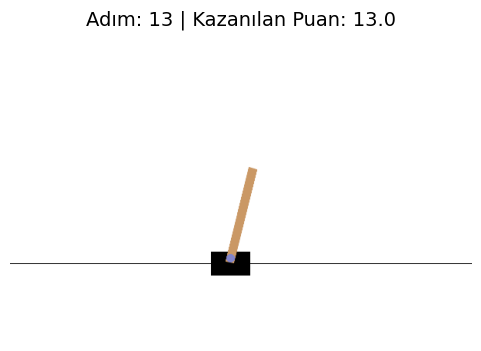


Oyun Bitti! Çubuk devrildi veya araba raydan çıktı.

--- MAÇ ÖZETİ VE AJANIN KARAR GÜNLÜĞÜ ---


,Adım,Hamle,Konum (X),Çubuk Açısı
0,1,Sağa İt,0.032,0.043
1,2,Sola İt,0.031,0.043
2,3,Sola İt,0.034,0.036
3,4,Sola İt,0.033,0.036
4,5,Sağa İt,0.028,0.041
5,6,Sola İt,0.020,0.053
6,7,Sola İt,0.015,0.059
7,8,Sola İt,0.006,0.071
8,9,Sola İt,-0.007,0.090
9,10,Sağa İt,-0.024,0.115


In [2]:
import gymnasium as gym
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time
import pandas as pd # Loglarımızı oyun sonunda şık bir tablo yapmak için ekledik

# 1. ORTAMI YARATMA VE BAŞLANGIÇ
# render_mode="rgb_array" -> Bize oyunun o anki resmini (piksellerini) bir matris olarak verir
oyun_ortami = gym.make("CartPole-v1", render_mode="rgb_array")

# Oyunu sıfırlarız. 'mevcut_durum' içinde arabanın konumu ve çubuğun açısı gibi 4 adet sayı vardır.
mevcut_durum, _ = oyun_ortami.reset()

toplam_puan = 0

# Her adımda yaşananları buraya bir sözlük (dictionary) olarak ekleyeceğiz
hamle_gunlugu = [] 

# 2. GÖRSELLEŞTİRME İÇİN ÇİZİM ALANI (FIGURE) HAZIRLIĞI
# matplotlib ile 6x4 inç boyutlarında boş bir tuval açıyoruz
fig, ax = plt.subplots(figsize=(6, 4))

print("Simülasyon başlıyor...")
time.sleep(1) # Başlamadan önce 1 saniye bekle

# 3. OYUN DÖNGÜSÜ (Maksimum 50 adım sürecek)
for adim in range(50): 
    
    # -- AJANIN KARARI --
    # Ajan rastgele bir hamle yapıyor (0: Sola İt, 1: Sağa İt)
    secilen_hamle = oyun_ortami.action_space.sample() 
    hamle_metni = "Sağa İt" if secilen_hamle == 1 else "Sola İt"
    
    # -- YENİ: DURUMU LİSTEYE KAYDETME (LOGLAMA) --
    # Hamleyi oyuna göndermeden hemen önce, o anki durumu günlüğümüze not ediyoruz.
    anlik_kayit = {
        "Adım": adim + 1,
        "Hamle": hamle_metni,
        "Konum (X)": round(mevcut_durum[0], 3), # Arabanın merkezden uzaklığı
        "Çubuk Açısı": round(mevcut_durum[2], 3) # Çubuğun eğimi (0'a yakın olmalı)
    }
    hamle_gunlugu.append(anlik_kayit) # Notu listeye ekle
    
    # -- ORTAMIN TEPKİSİ --
    # Seçtiğimiz hamleyi uyguluyoruz ve yeni duruma geçiyoruz
    mevcut_durum, odul, oyun_bitti_mi, zaman_doldu_mu, bilgi = oyun_ortami.step(secilen_hamle)
    toplam_puan += odul
    
    # --- GÖRSELLEŞTİRME (ANİMASYON) KISMI ---
    # Ortamdan o anki kareyi (resmi) alıyoruz
    kare = oyun_ortami.render()
    
    # Tuvali temizle ve yeni resmi çizdir
    ax.clear()
    ax.imshow(kare)
    ax.axis('off') # Resmin etrafındaki x-y ekseni çizgilerini gizle
    ax.set_title(f"Adım: {adim+1} | Kazanılan Puan: {toplam_puan}", fontsize=14)
    
    # Jupyter'de animasyon hissi vermek için:
    # clear_output(wait=True) -> Bir önceki çizilmiş resmi siler
    # display(fig) -> Yeni resmi ekrana basar
    clear_output(wait=True)
    display(fig)
    time.sleep(0.1) # İnsan gözünün kareleri algılayabilmesi için 0.1 saniye yavaşlatıyoruz
    # ----------------------------
    
    # BİTİŞ KONTROLÜ
    # Çubuk 12 dereceyi geçerse veya araba ekrandan çıkarsa döngüyü kır
    if oyun_bitti_mi or zaman_doldu_mu:
        print(f"\nOyun Bitti! Çubuk devrildi veya araba raydan çıktı.")
        break

# İşimiz bittiğinde oyunu ve çizim tuvalini kapatıyoruz (Hafıza tasarrufu için)
oyun_ortami.close()
plt.close(fig)

# 4. LOGLARI TABLO OLARAK EKRANA BASMA
# Tutulan listeyi Pandas DataFrame'ine çeviriyoruz (Jupyter'de harika görünür)
df_loglar = pd.DataFrame(hamle_gunlugu)

print("\n--- MAÇ ÖZETİ VE AJANIN KARAR GÜNLÜĞÜ ---")
# display() fonksiyonu Jupyter'e özel, tabloları HTML formatında şık gösterir
display(df_loglar)